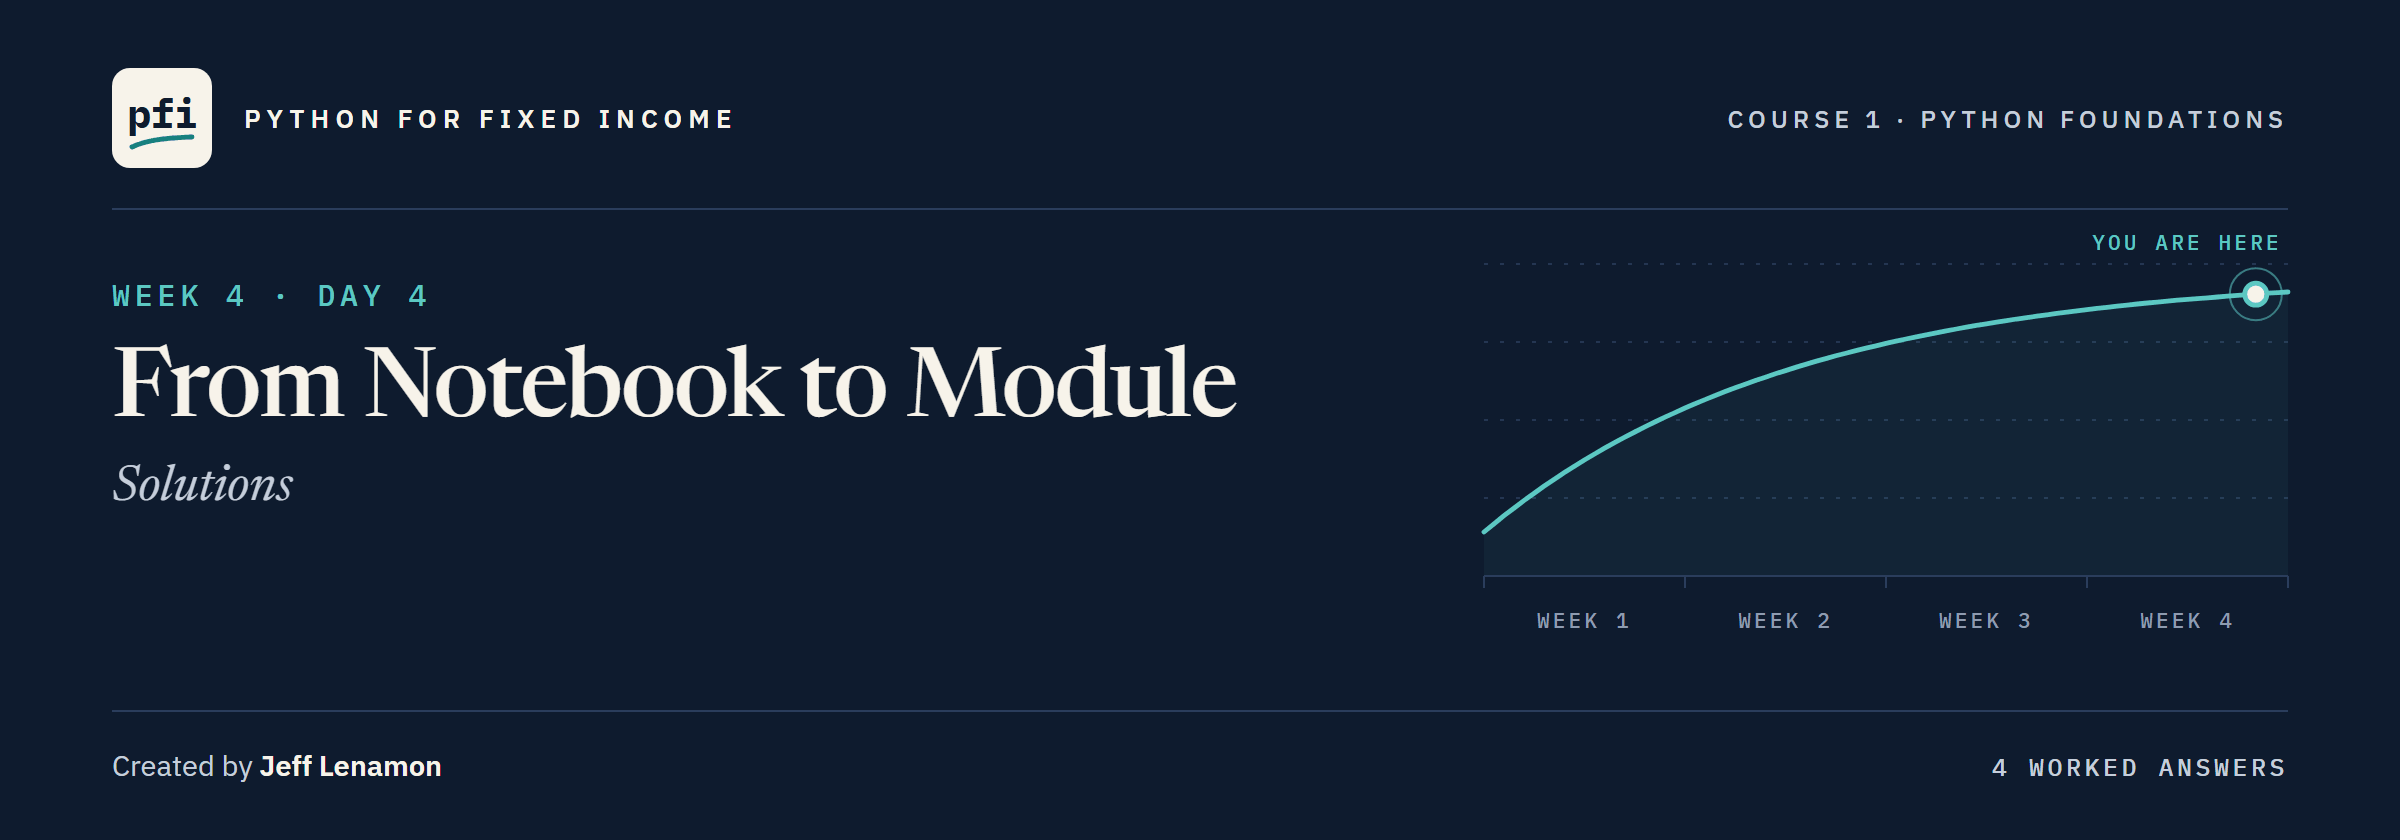

# From Notebook to Module: Solutions

Week 4, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day4/19_from_notebook_to_module_solutions.ipynb)

## Exercises

Each answer is followed by the check cell from the teaching notebook.
Run the next three cells first: the module, as the lesson left it without its program block; `check`; and the loader.

In [1]:
%%writefile desk_tools.py
"""Desk tools: load, clean, check, summarize, and report a month-end holdings extract.

From Python for Fixed Income, Course 1, From Notebook to Module. All data is synthetic.
"""
import pandas as pd


def load_holdings(path: str) -> pd.DataFrame:
    """Read a holdings extract from a CSV file and return it as it arrived.

    path is the file name or the web address of the CSV. The CUSIP is read as text.
    """
    return pd.read_csv(path, dtype={'cusip': str})


def clean_holdings(raw):
    """Apply the desk's cleaning decisions to an extract and return the cleaned table.

    The six decisions of the EDA notebook, in the same order:
      1. Exact duplicate rows are removed, keeping the first of each.
      2. Tickers are tidied: no spaces at either end, all capitals.
      3. A price dated on another day than the as-of date is flagged in a new column,
         stale_price. The price is not changed.
      4. A missing rating is labelled 'Not rated'. The bond stays in the book.
      5. A yield entered as a decimal is multiplied by 100. The test is the IQR rule:
         a yield below the first quartile less 1.5 times the IQR.
      6. Bonds with very wide spreads are real, and they are kept.

    raw is not changed. The cleaned table has one more column than raw: stale_price.
    """
    # work in a copy, so that the table passed in stays as it arrived
    book = raw.copy()

    # decision 1: remove the repeated rows and renumber the rows from 0
    book = book.drop_duplicates().reset_index(drop=True)

    # decision 2: tidy the tickers
    book['ticker'] = book['ticker'].str.strip().str.upper()

    # decision 3: flag the stale prices, and leave them as they are
    book['stale_price'] = book['price_date'] != book['as_of_date']

    # decision 4: label the missing ratings
    book['rating'] = book['rating'].fillna('Not rated')

    # decision 5: yields in percent, where one was entered as a decimal
    q1 = book['yield_pct'].quantile(0.25)
    q3 = book['yield_pct'].quantile(0.75)
    lower_limit = q1 - 1.5 * (q3 - q1)
    entered_as_decimal = book['yield_pct'] < lower_limit
    book.loc[entered_as_decimal, 'yield_pct'] = (
        book.loc[entered_as_decimal, 'yield_pct'] * 100).round(3)

    # decision 6: the very wide bonds are real and they stay, so there is no line for them

    return book


def check_totals(book, bonds, face, market_value):
    """Test a table against its three control totals. Raise ValueError if any one does not match.

    bonds is the number of rows the table should have. face and market_value are in dollars.
    Nothing is returned: if the function finishes without an error, the table matches.
    """
    found_bonds = len(book)
    found_face = book['par_held'].sum()
    found_value = book['market_value'].sum()

    # collect every mismatch, so that one message reports them all
    problems = []
    if found_bonds != bonds:
        problems.append(f'{found_bonds:,} rows against {bonds:,} bonds')
    if found_face != face:
        problems.append(f'face of {found_face:,} against {face:,} dollars')
    # market value has cents, so allow half a cent for decimal arithmetic
    if abs(found_value - market_value) > 0.005:
        problems.append(f'market value of {found_value:,.2f} against {market_value:,.2f} dollars')

    if problems:
        raise ValueError('control totals do not match: ' + '; '.join(problems))


def summarize(book):
    """Return the headline table of a cleaned book: one row, one column for each figure.

    face and market_value are in dollars, mean_oas in basis points, mean_yield in percent.
    not_rated and stale_prices count the bonds that clean_holdings labelled or flagged.
    """
    headline = {
        'bonds': len(book),
        'face': book['par_held'].sum(),
        'market_value': book['market_value'].sum(),
        'mean_oas': round(book['oas'].mean(), 2),
        'mean_yield': round(book['yield_pct'].mean(), 3),
        'not_rated': (book['rating'] == 'Not rated').sum(),
        'stale_prices': book['stale_price'].sum(),
    }
    # a list holding one dictionary becomes a table with one row
    return pd.DataFrame([headline])


def write_report(book, summary, path):
    """Write the month-end workbook to path: the headline table on a sheet named 'summary'
    and the cleaned book on a sheet named 'book'.
    """
    with pd.ExcelWriter(path) as writer:
        summary.to_excel(writer, sheet_name='summary', index=False)
        book.to_excel(writer, sheet_name='book', index=False)


def count_changes(raw, book):
    """Count what clean_holdings changed: one row, one column for each decision.

    raw is the extract as it arrived and book is the table clean_holdings returned for it.
    """
    # the extract with its repeated rows removed lines up row for row with the cleaned book
    kept = raw.drop_duplicates().reset_index(drop=True)
    counts = {
        'rows_removed': len(raw) - len(book),
        'tickers_tidied': (kept['ticker'] != book['ticker']).sum(),
        'stale_prices_flagged': book['stale_price'].sum(),
        'ratings_labelled': kept['rating'].isna().sum(),
        'yields_corrected': (kept['yield_pct'] != book['yield_pct']).sum(),
    }
    return pd.DataFrame([counts])

Writing desk_tools.py


In [2]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [3]:
import importlib
import os
import sys

import pandas as pd

# no __pycache__ folder, as in the lesson
sys.dont_write_bytecode = True
# import the module the cell above wrote; reload() makes sure this is that version
import desk_tools
importlib.reload(desk_tools)
if os.path.exists('../../../data/holdings_messy.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
expected_bonds = 200
expected_face = 489_000_000
expected_value = 490_819_215
raw = desk_tools.load_holdings(data_folder + 'holdings_messy.csv')
book = desk_tools.clean_holdings(raw)
desk_tools.check_totals(book, expected_bonds, expected_face, expected_value)
print(raw.shape, book.shape)

(204, 19) (200, 20)


### Exercise 1

The function goes into the file with `%%writefile -a`, run once: each run appends, so a second run would put a second copy in the file.

In [4]:
%%writefile -a desk_tools.py


def sector_totals(book):
    """Return the market value of each sector of a book, in dollars, largest sector first.

    book is a table with a sector column and a market_value column. A Series comes back,
    with the sector names as its labels.
    """
    totals = book.groupby('sector')['market_value'].sum()
    return totals.sort_values(ascending=False)

Appending to desk_tools.py


In [5]:
# the file changed, so reload before calling the new function
importlib.reload(desk_tools)
totals = desk_tools.sector_totals(book)
print(totals.head(3))
# the first label of the sorted Series, and its value
ex1_sector = totals.index[0]
ex1_value = totals.iloc[0]
print(ex1_sector, f'{ex1_value:,.2f}', f'{totals.sum():,.2f}')

sector
Materials     71701617.5
Financials    68219672.5
Consumer      56629597.5
Name: market_value, dtype: float64
Materials 71,701,617.50 490,819,215.00


Materials is the largest sector, at 71,701,617.50 dollars.
The ten sectors add up to 490,819,215.00, the control total: a grouped table that does not add up to the book has lost rows.
Without the reload, the call fails with the `AttributeError` of Predict 1.

In [6]:
check('Exercise 1 largest sector', ex1_sector, 'Materials')
check('Exercise 1 market value', ex1_value, 71701617.5)

Exercise 1 largest sector: correct
Exercise 1 market value: correct


### Exercise 2

In [7]:
def check_unique(table, column):
    """Raise ValueError if a value of the column repeats an earlier one. Return nothing."""
    # duplicated() marks a value True when it has appeared before
    repeats = table[column].duplicated().sum()
    if repeats > 0:
        raise ValueError(f'{repeats} repeated values in {column}')


# the cleaned book: no error, so the print is reached
check_unique(book, 'cusip')
print('book: every CUSIP appears once')
# the extract as received: catch the error and keep its message
try:
    check_unique(raw, 'cusip')
    ex2_message = 'no error'
except ValueError as error:
    ex2_message = str(error)
print('raw:', ex2_message)

book: every CUSIP appears once
raw: 4 repeated values in cusip


The cleaned book passes without a word; the extract raises `4 repeated values in cusip`, the four rows sent twice.
The line `ex2_message = 'no error'` runs only if the check did not raise, so a check that wrongly passed still leaves a value to inspect.

In [8]:
check('Exercise 2 message', ex2_message, '4 repeated values in cusip')

Exercise 2 message: correct


### Exercise 3

In [9]:
# the lesson's lines, on the clean September file
report_file = 'exercise_report.xlsx'
raw_clean = desk_tools.load_holdings(data_folder + 'holdings.csv')
book_clean = desk_tools.clean_holdings(raw_clean)
desk_tools.check_totals(book_clean, expected_bonds, expected_face, expected_value)
summary_clean = desk_tools.summarize(book_clean)
desk_tools.write_report(book_clean, summary_clean, report_file)
# both sheets back, then the workbook deleted
book_back = pd.read_excel(report_file, sheet_name='book', dtype={'cusip': str})
summary_back = pd.read_excel(report_file, sheet_name='summary')
os.remove(report_file)
ex3_rows = len(book_back)
ex3_yield = summary_back.loc[0, 'mean_yield']
ex3_stale = summary_back.loc[0, 'stale_prices']
ex3_left = os.path.exists(report_file)
print(ex3_rows, ex3_yield, ex3_stale, ex3_left)

200 6.088 0 False


200 rows, a mean yield of 6.088 percent, and 0 stale prices; the workbook is gone.
Only the file name changed from the lesson's run, and the mean yield is the one the cleaned messy extract gave: two routes, one book.

In [10]:
check('Exercise 3 rows on the book sheet', ex3_rows, 200)
check('Exercise 3 mean yield', ex3_yield, 6.088)
check('Exercise 3 stale prices', ex3_stale, 0)
check('Exercise 3 workbook left behind', ex3_left, False)

Exercise 3 rows on the book sheet: correct
Exercise 3 mean yield: correct
Exercise 3 stale prices: correct
Exercise 3 workbook left behind: correct


### Exercise 4: AI check

The two bonds have the same market value, so the weighted average is the simple average of 900 and 100: 500 basis points.
The assistant's function gave 633.33 and 184.52 with no error; 184.52 looks plausible for this book.
The bug is the weight: the docstring says market value, and the code weighted by `par_held`, which counts the first bond, 2,000,000 of face at a price near 50, twice.
The fix uses `market_value` in both places; the book's figure becomes 180.46 basis points, 4.06 lower.

In [11]:
def weighted_mean_oas(book):
    """Return the average OAS of a book in basis points, weighted by market value."""
    # weight each bond's OAS by its market value
    weighted_sum = (book['oas'] * book['market_value']).sum()
    return weighted_sum / book['market_value'].sum()


two_bonds = pd.DataFrame({'oas': [900, 100], 'par_held': [2_000_000, 1_000_000],
                          'market_value': [1_000_000.0, 1_000_000.0]})
# the test, with the answer worked by hand: it fails on the assistant's version
assert weighted_mean_oas(two_bonds) == 500, f'expected 500, found {weighted_mean_oas(two_bonds)}'
ex4_two_bonds = round(weighted_mean_oas(two_bonds), 2)
ex4_book = round(weighted_mean_oas(book), 2)
print(ex4_two_bonds, ex4_book)

500.0 180.46


In [12]:
check('Exercise 4 two bonds', ex4_two_bonds, 500.0)
check('Exercise 4 the book', ex4_book, 180.46)

Exercise 4 two bonds: correct
Exercise 4 the book: correct


### Tidying Up

In [13]:
# delete every file this notebook wrote, if it is still there
for file in ['desk_tools.py', 'month_end_report.xlsx', 'exercise_report.xlsx']:
    if os.path.exists(file):
        os.remove(file)
    print(file, os.path.exists(file))

desk_tools.py False
month_end_report.xlsx False
exercise_report.xlsx False


[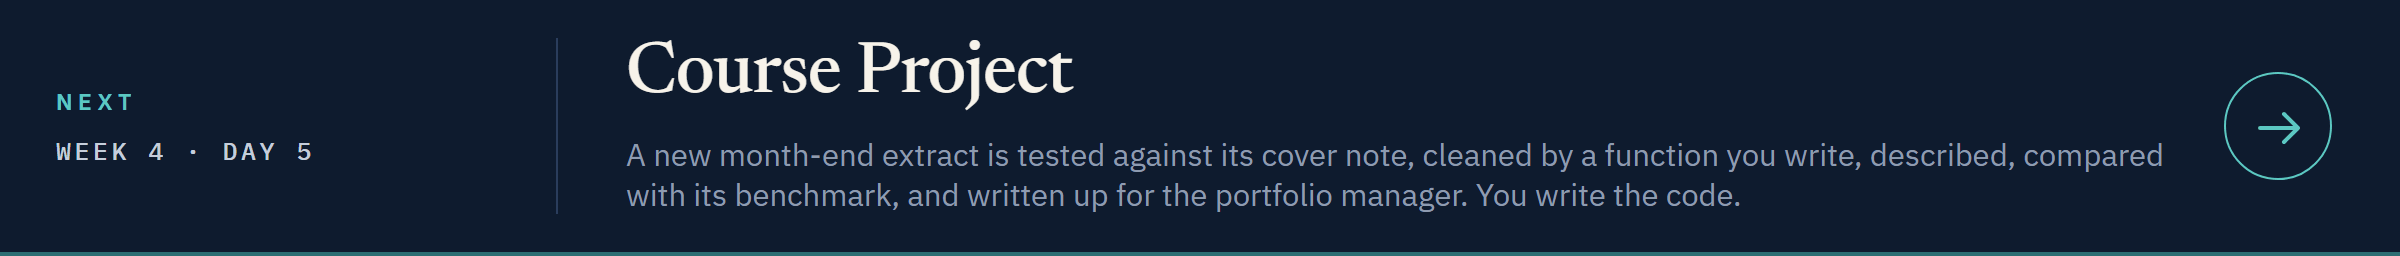](../day5/course1_project.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day5/course1_project.ipynb)